# С/р-1. Регрессия Малыхина Елена Евгеньевна БИ 1 курс 15 группа

Датасет: Anime Dataset 2022 https://www.kaggle.com/datasets/vishalmane10/anime-dataset-2022

Целевой признак: Rating - средняя оценка аниме пользователями Anime Planet.

Задача: регрессия - предсказать рейтинг аниме по его характеристикам (тип, число эпизодов, студия, сезон и год выхода, теги и т.д.).

In [1]:
# импортируем все нужные библиотеки
import numpy as np                                   
import pandas as pd                                  
import matplotlib.pyplot as plt                      
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer  
from sklearn.pipeline import Pipeline              
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# читаем датасет
df = pd.read_csv("Anime.csv")  
# печатаем размерность
print("Размерность:", df.shape)
# первые 5 строк
df.head()

Размерность: (18495, 17)


,Rank,Name,Japanese_name,Type,Episodes,Studio,Release_season,Tags,Rating,Release_year,End_year,Description,Content_Warning,Related_Mange,Related_anime,Voice_actors,staff
0,1,Demon Slayer: Kimetsu no Yaiba - Entertainment...,Kimetsu no Yaiba: Yuukaku-hen,TV,NaN,ufotable,Fall,"Action, Adventure, Fantasy, Shounen, Demons, H...",4.60,2021.0,NaN,'Tanjiro and his friends accompany the Hashira...,Explicit Violence,Demon Slayer: Kimetsu no Yaiba,"Demon Slayer: Kimetsu no Yaiba, Demon Slayer: ...","Inosuke Hashibira : Yoshitsugu Matsuoka, Nezuk...","Koyoharu Gotouge : Original Creator, Haruo Sot..."
1,2,Fruits Basket the Final Season,Fruits Basket the Final,TV,13.0,TMS Entertainment,Spring,"Drama, Fantasy, Romance, Shoujo, Animal Transf...",4.60,2021.0,NaN,'The final arc of Fruits Basket.',"Emotional Abuse,, Mature Themes,, Physical Abu...","Fruits Basket, Fruits Basket Another","Fruits Basket 1st Season, Fruits Basket 2nd Se...","Akito Sohma : Maaya Sakamoto, Kyo Sohma : Yuum...","Natsuki Takaya : Original Creator, Yoshihide I..."
2,3,Mo Dao Zu Shi 3,The Founder of Diabolism 3,Web,12.0,B.C MAY PICTURES,NaN,"Fantasy, Ancient China, Chinese Animation, Cul...",4.58,2021.0,NaN,'The third season of Mo Dao Zu Shi.',NaN,Grandmaster of Demonic Cultivation: Mo Dao Zu ...,"Mo Dao Zu Shi 2, Mo Dao Zu Shi Q","Lan Wangji, Wei Wuxian, Jiang Cheng, Jin Guang...","Mo Xiang Tong Xiu : Original Creator, Xiong Ke..."
3,4,Fullmetal Alchemist: Brotherhood,Hagane no Renkinjutsushi: Full Metal Alchemist,TV,64.0,Bones,Spring,"Action, Adventure, Drama, Fantasy, Mystery, Sh...",4.58,2009.0,2010.0,"""The foundation of alchemy is based on the law...","Animal Abuse,, Mature Themes,, Violence,, Dome...","Fullmetal Alchemist, Fullmetal Alchemist (Ligh...","Fullmetal Alchemist: Brotherhood Specials, Ful...","Alphonse Elric : Rie Kugimiya, Edward Elric : ...","Hiromu Arakawa : Original Creator, Yasuhiro Ir..."
4,5,Attack on Titan 3rd Season: Part II,Shingeki no Kyojin Season 3: Part II,TV,10.0,WIT Studio,Spring,"Action, Fantasy, Horror, Shounen, Dark Fantasy...",4.57,2019.0,NaN,'The battle to retake Wall Maria begins now! W...,"Cannibalism,, Explicit Violence","Attack on Titan, Attack on Titan: End of the W...","Attack on Titan, Attack on Titan 2nd Season, A...","Armin Arlelt : Marina Inoue, Eren Jaeger : Yuu...","Hajime Isayama : Original Creator, Tetsurou Ar..."


In [3]:
# посмотрим типы данных и число непустых значений по столбцам
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18495 entries, 0 to 18494
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Rank             18495 non-null  int64  
 1   Name             18495 non-null  str    
 2   Japanese_name    7938 non-null   str    
 3   Type             18495 non-null  str    
 4   Episodes         9501 non-null   float64
 5   Studio           12018 non-null  str    
 6   Release_season   4116 non-null   str    
 7   Tags             18095 non-null  str    
 8   Rating           15364 non-null  float64
 9   Release_year     18112 non-null  float64
 10  End_year         2854 non-null   float64
 11  Description      18491 non-null  str    
 12  Content_Warning  1840 non-null   str    
 13  Related_Mange    7627 non-null   str    
 14  Related_anime    10063 non-null  str    
 15  Voice_actors     15309 non-null  str    
 16  staff            13005 non-null  str    
dtypes: float64(4), int64(1)

In [4]:
# сколько пропусков в каждом столбце
df.isna().sum().sort_values(ascending=False)

Content_Warning    16655
End_year           15641
Release_season     14379
Related_Mange      10868
Japanese_name      10557
Episodes            8994
Related_anime       8432
Studio              6477
staff               5490
Voice_actors        3186
Rating              3131
Tags                 400
Release_year         383
Description            4
Rank                   0
Name                   0
Type                   0
dtype: int64

In [5]:
# проверяем, есть ли полностью одинаковые строки
print("Полных дубликатов:", df.duplicated().sum())

Полных дубликатов: 0


Вывод по анализу: в датасете есть и числовые, и текстовые столбцы, а также много пропусков. Дубликатов нет.

In [6]:
# теперь подготавливаем сам целевой признак
# смотрим, есть ли пропуски в целевом признаке
print("Пропусков в Rating:", df["Rating"].isna().sum())
# строки без цели обучать нельзя - удаляем их
df = df.dropna(subset=["Rating"])
# статистика целевого признака
df["Rating"].describe()

Пропусков в Rating: 3131


count    15364.000000
mean         3.355133
std          0.400624
min          0.960000
25%          3.130000
50%          3.360000
75%          3.590000
max          4.600000
Name: Rating, dtype: float64

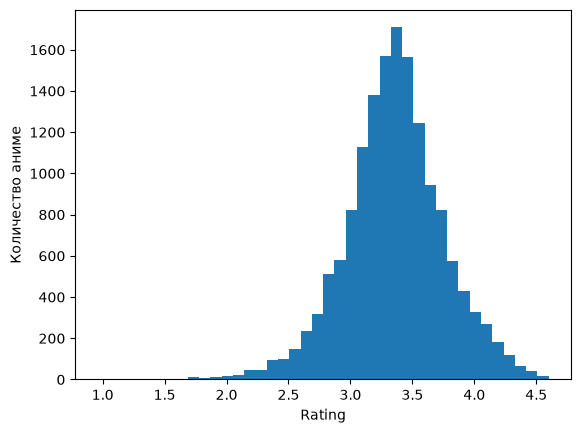

In [7]:
# выведем гистограмму рейтинга
plt.hist(df["Rating"], bins=40)
plt.xlabel("Rating")
plt.ylabel("Количество аниме")
plt.show()

Вывод: рейтинг распределён почти нормально, с центром около 3.3 - преобразовывать цель (логарифмировать и т.п.) не нужно.

НО столбец Rank (позиция в рейтинге сайта) вычисляется из самого рейтинга. Если оставить его в признаках, модель подсмотрит ответ и метрики будут отличными, но бесполезными. Поэтому Rank удаляем. Столбцы Name и Japanese_name - уникальные названия, они не несут обобщаемой информации, их тоже удаляем.

In [8]:
# убираем Rank и уникальные названия
data = df.drop(columns=["Rank", "Name", "Japanese_name"])
# проверим размерность после удаления
data.shape

(15364, 14)

Сделаем некую подгатовку признаков

- Tags - строка с тегами через запятую: заменяем на количество тегов, чем больше тегов, тем сложнее аниме;
- Description, Content_Warning, Related_Mange, Related_anime, Voice_actors, staff - длинные текстовые поля, в рамках линейной регрессии их не используем, удаляем;
- Studio - слишком много уникальных значений: оставляем самые частые студии, остальные объединяем в Other, пропуски - Unknown;
- Type, Release_season - делаем небольшие категории, а пропуски заполняем Unknown;
- числовые пропуски (Episodes, Release_year, End_year) заполним медианой внутри пайплайна.

In [9]:
data["n_Tags"] = data["Tags"].fillna("").str.split(",").apply(
     # считаем число непустых тегов в строке
    lambda parts: len([p for p in parts if p.strip() != ""]))
data = data.drop(columns=["Tags", "Description", "Content_Warning", "Related_Mange",
                          "Related_anime", "Voice_actors", "staff"])   # удаляем текстовые столбцы, которые не используем
data.info()    

<class 'pandas.DataFrame'>
Index: 15364 entries, 0 to 17355
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Type            15364 non-null  str    
 1   Episodes        8255 non-null   float64
 2   Studio          10982 non-null  str    
 3   Release_season  3991 non-null   str    
 4   Rating          15364 non-null  float64
 5   Release_year    15344 non-null  float64
 6   End_year        2591 non-null   float64
 7   n_Tags          15364 non-null  int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 1.3 MB


In [10]:
for col in ["Episodes", "Release_year", "End_year"]:
    # приводим к числу (на случай, если значения записаны текстом
    data[col] = pd.to_numeric(data[col], errors="coerce")

# пропуски в студии переделываем в Unknown
data["Studio"] = data["Studio"].fillna("Unknown")
#берем 30 самых частых студий
top_studios = data["Studio"].value_counts().head(30).index
# остальные студии запишем в Other
data["Studio"] = data["Studio"].where(data["Studio"].isin(top_studios), "Other")

# пропуски переделываем в Unknown
data["Type"] = data["Type"].fillna("Unknown")
data["Release_season"] = data["Release_season"].fillna("Unknown")
# смотрим, где еще пропуски остались
data.isna().sum()

Type                  0
Episodes           7109
Studio                0
Release_season        0
Rating                0
Release_year         20
End_year          12773
n_Tags                0
dtype: int64

- пропуски в категориях заполнили Unknown - «неизвестно» само по себе может быть информативным;
- числовые пропуски остались (Episodes, End_year, Release_year) - заполним медианой внутри пайплайна: медиана устойчива к выбросам (аниме на сотни серий), а при заполнении внутри пайплайна медиана считается только по обучающей выборке, без утечки из теста.

In [11]:
# теперь разбиваем на обучающую и тестовую выборки 
# категориальные признаки
cat_features = ["Type", "Studio", "Release_season"]
# числовые признаки
num_features = ["Episodes", "Release_year", "End_year", "n_Tags"]

# признаки
X = data.drop(columns=["Rating"])
# целевая переменная
y = data["Rating"]

# 80% - обучение, 20% - тест (тест трогаем только для финальной оценки)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

# схема кросс-валидации для подбора гиперпараметров
kf = KFold(n_splits=5, shuffle=True, random_state=42)

Train: (12291, 7)  Test: (3073, 7)


Используем несколько метрик, потому что каждая показывает своё:

RMSE - корень из среднеквадратичной ошибки, в тех же единицах, что рейтинг; сильнее штрафует крупные промахи. Главная метрика для выбора модели и подбора гиперпараметров.
MAE - средняя абсолютная ошибка, понятная интерпретация («в среднем ошибаемся на X баллов»).
MAPE - ошибка в процентах; подходит, т.к. рейтинг всегда > 0.
MASE - ошибка модели относительно «наивного» прогноза (среднее по train); значение < 1 - модель лучше наивной.
R² - доля объяснённой дисперсии (1 - идеально, 0 - как константа).

Но главная RMSE - она измеряется в тех же единицах, что и целевой признак (в баллах рейтинга), что делает её легко интерпретируемой. Например, RMSE = 0.3 означает типичную ошибку порядка 0.3 балла.
RMSE сильнее штрафует модель за большие промахи (так как ошибка возводится в квадрат), что для нас важно: мы не хотим, чтобы модель грубо ошибалась на отдельных аниме.

In [12]:
def calculate_mase(y_train, y_true, y_pred):
    # ошибка наивной модели (всегда предсказывает среднее)
    naive_mae = np.mean(np.abs(y_train - y_train.mean()))
    # во сколько раз наша ошибка меньше/больше наивной
    return mean_absolute_error(y_true, y_pred) / naive_mae

def regression_metrics(y_train, y_true, y_pred, model_name):
    # средний квадрат ошибки
    mse = mean_squared_error(y_true, y_pred)
    #  возвращаем словарь со всеми метриками для итоговой таблицы
    return {
        "Модель": model_name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE, %": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "MASE": calculate_mase(y_train, y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }

# сюда будем складывать результаты всех экспериментов
results = []

Попробуем линейную регрессию

In [13]:
prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), # пропуски в числах делаем медиану
                      ("scaler", StandardScaler())]), num_features), # стандартизация числовых признаков
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features), # one-hot кодирование категорий
])

lin = Pipeline([
    ("prep", prep), # обработка признаков
    ("model", LinearRegression()), # обычная линейная регрессия
])
cv_scores = cross_val_score(lin, X_train, y_train, cv=kf, scoring="r2") # R² на кросс-валидации (только по train)
print("R² на кросс-валидации:", cv_scores.round(3), "| среднее:", cv_scores.mean().round(3))

lin.fit(X_train, y_train) # обучаем на всей обучающей выборке
results.append(regression_metrics(y_train, y_test, lin.predict(X_test), "1. Линейная регрессия"))
pd.DataFrame(results).round(3)

R² на кросс-валидации: [0.224 0.225 0.208 0.241 0.258] | среднее: 0.231


,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244


Вывод: MASE = 0.869 < 1 и R² = 0.244 > 0 - признаки (тип, студия, год, число тегов) несут информацию о рейтинге, модель лучше наивной, которая всегда выдаёт среднее. Дальше проверим, поможет ли учёт нелинейности

Вышло не очень, пробуем линейную регрессию + полиномиальные признаки (степень 2)

In [14]:
prep_poly = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False)), # квадраты и попарные произведения числовых признаков
                      ("scaler", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

poly2 = Pipeline([
    ("prep", prep_poly),
    ("model", LinearRegression()),
])
cv_scores = cross_val_score(poly2, X_train, y_train, cv=kf, scoring="r2") # R² на кросс-валидации
print("R² на кросс-валидации:", cv_scores.round(3), "| среднее:", cv_scores.mean().round(3))

poly2.fit(X_train, y_train)
results.append(regression_metrics(y_train, y_test, poly2.predict(X_test), "2. Полиномиальная, degree=2"))
pd.DataFrame(results).round(3)

R² на кросс-валидации: [0.252 0.24  0.233 0.25  0.274] | среднее: 0.25


,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244
1,"2. Полиномиальная, degree=2",0.119,0.345,0.261,8.242,0.859,0.260


Вывод: RMSE снизился с 0.349 до 0.345, R² вырос с 0.244 до 0.260 (на кросс-валидации с 0.231 до 0.250). Метрики улучшились.

Эксперимент 3 - пробуем Ridge-регрессию (L2-регуляризация), подбор alpha

In [15]:
ridge = Pipeline([
    ("prep", prep), # без полиномов - меняем только тип модели
    ("model", Ridge()), # линейная модель со штрафом на квадраты весов
])
ridge_search = GridSearchCV(
    ridge,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}, # сила регуляризации от слабой до очень сильной
    scoring="neg_root_mean_squared_error", # оптимизируем RMSE
    cv=kf,
)
# перебор alpha по 5-fold кросс-валидации на train
ridge_search.fit(X_train, y_train)
print("Лучший alpha:", ridge_search.best_params_)
print("RMSE на кросс-валидации:", round(-ridge_search.best_score_, 4))
results.append(regression_metrics(
    y_train, y_test, ridge_search.predict(X_test),
    f"3. Ridge, alpha={ridge_search.best_params_['model__alpha']}"))
pd.DataFrame(results).round(3)

Лучший alpha: {'model__alpha': 10}
RMSE на кросс-валидации: 0.3509


,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244
1,"2. Полиномиальная, degree=2",0.119,0.345,0.261,8.242,0.859,0.260
2,"3. Ridge, alpha=10",0.122,0.349,0.264,8.339,0.869,0.243


Вывод: Ridge с alpha=10 дал те же метрики, что обычная линейная регрессия (RMSE 0.349). Регуляризация не нужна: признаков немного, переобучения нет.

Попробуем Lasso-регрессию (L1-регуляризация), подбор alpha

In [16]:
lasso = Pipeline([
    ("prep", prep),
    ("model", Lasso(max_iter=20000)), # L1-штраф: обнуляет веса ненужных признаков
])
lasso_search = GridSearchCV(
    lasso,
    param_grid={"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1]}, # для Lasso нужны меньшие alpha, иначе всё занулится
    scoring="neg_root_mean_squared_error",
    cv=kf,
)
lasso_search.fit(X_train, y_train)
print("Лучший alpha:", lasso_search.best_params_)
print("RMSE на кросс-валидации:", round(-lasso_search.best_score_, 4))
results.append(regression_metrics(
    y_train, y_test, lasso_search.predict(X_test),
    f"4. Lasso, alpha={lasso_search.best_params_['model__alpha']}"))
pd.DataFrame(results).round(3)

Лучший alpha: {'model__alpha': 0.0001}
RMSE на кросс-валидации: 0.3509


,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244
1,"2. Полиномиальная, degree=2",0.119,0.345,0.261,8.242,0.859,0.260
2,"3. Ridge, alpha=10",0.122,0.349,0.264,8.339,0.869,0.243
3,"4. Lasso, alpha=0.0001",0.122,0.349,0.264,8.336,0.869,0.244


Вывод: Lasso выбрал минимальный alpha=0.0001 - сильное зануление признаков не помогает, результат совпадает с линейной регрессией (RMSE 0.349)

Попробуем Ridge + полиномиальные признаки (степень 2), подбор alpha

In [17]:
ridge_poly = Pipeline([
    ("prep", prep_poly), # препроцессинг с полиномами из эксперимента 2
    ("model", Ridge()),
])
ridge_poly_search = GridSearchCV(
    ridge_poly,
    param_grid={"model__alpha": [0.1, 1, 10, 100, 1000]}, # сила регуляризации (с полиномами признаков больше)
    scoring="neg_root_mean_squared_error",
    cv=kf,
)
ridge_poly_search.fit(X_train, y_train)
print("Лучший alpha:", ridge_poly_search.best_params_)
print("RMSE на кросс-валидации:", round(-ridge_poly_search.best_score_, 4))
results.append(regression_metrics(
    y_train, y_test, ridge_poly_search.predict(X_test),
    f"5. Ridge+poly, degree=2, alpha={ridge_poly_search.best_params_['model__alpha']}"))
pd.DataFrame(results).round(3)

Лучший alpha: {'model__alpha': 0.1}
RMSE на кросс-валидации: 0.347


,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244
1,"2. Полиномиальная, degree=2",0.119,0.345,0.261,8.242,0.859,0.260
2,"3. Ridge, alpha=10",0.122,0.349,0.264,8.339,0.869,0.243
3,"4. Lasso, alpha=0.0001",0.122,0.349,0.264,8.336,0.869,0.244
4,"5. Ridge+poly, degree=2, alpha=0.1",0.120,0.346,0.261,8.249,0.860,0.258


Вывод: Ridge+poly (RMSE 0.346) не лучше обычных полиномов (0.345) - регуляризация здесь не нужна, переобучения нет.

In [18]:
# итоговое сравнение
# сортируем по RMSE: лучшая модель сверху
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df.round(3)

,Модель,MSE,RMSE,MAE,"MAPE, %",MASE,R²
0,"2. Полиномиальная, degree=2",0.119,0.345,0.261,8.242,0.859,0.260
1,"5. Ridge+poly, degree=2, alpha=0.1",0.120,0.346,0.261,8.249,0.860,0.258
2,"4. Lasso, alpha=0.0001",0.122,0.349,0.264,8.336,0.869,0.244
3,1. Линейная регрессия,0.122,0.349,0.264,8.339,0.869,0.244
4,"3. Ridge, alpha=10",0.122,0.349,0.264,8.339,0.869,0.243


In [19]:
 # лучшая модель выводится
best = results_df.iloc[0]
print("Лучшая модель:", best["Модель"])
print(f"RMSE = {best['RMSE']:.3f}, MAE = {best['MAE']:.3f}, MAPE = {best['MAPE, %']:.1f}%, "
      f"MASE = {best['MASE']:.3f}, R² = {best['R²']:.3f}")

Лучшая модель: 2. Полиномиальная, degree=2
RMSE = 0.345, MAE = 0.261, MAPE = 8.2%, MASE = 0.859, R² = 0.260


## 9. Выводы

Задача: предсказание пользовательского рейтинга аниме Rating по типу, студии, сезону, году выхода, числу серий и числу тегов. Целевой признак непрерывный - задача регрессии.

Подготовка данных: удалены строки без рейтинга; удалён Rank (прямая утечка цели), названия и длинные текстовые поля; Tags заменены числом тегов; Studio сокращена до топ-30 + Other; пропуски в категориях заполнены Unknown, в числах - медианой внутри пайплайна (без утечки из теста).

Метрики: главная - RMSE, дополнительно MAE, MAPE, MASE (сравнение с наивной моделью «всегда среднее») и R².

Эксперименты по порядку: линейная регрессия -> полиномиальные признаки (степень 2) -> Ridge -> Lasso -> Ridge + полиномы. Гиперпараметры подбирались GridSearchCV по 5-fold кросс-валидации
только на обучающей выборке, тест использовался один раз для финальной оценки.

Итог: Лучшая модель - полиномиальная регрессия степени 2: RMSE = 0.345, MAE = 0.261, MAPE = 8.2%, MASE = 0.859, R² = 0.260. Это лучше наивной модели, которая всегда предсказывает среднее (MASE = 1, R² = 0). Ridge и Lasso качество не улучшили, полиномы дали небольшой прирост. 
Модель объясняет около 26% разброса рейтинга: рейтинг зависит от сюжета и вкусов зрителей, которые метаданными не описать.